In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv('insurance.csv')

In [6]:
print(df.head())
print(df.shape)
print(df.describe())
print(df.isnull().sum())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
(1338, 7)
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010
age         0
sex         0
bmi         0
children    0
smoker      0
regio

13270.422265141257
smoker
no     1064
yes     274
Name: count, dtype: int64
smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64


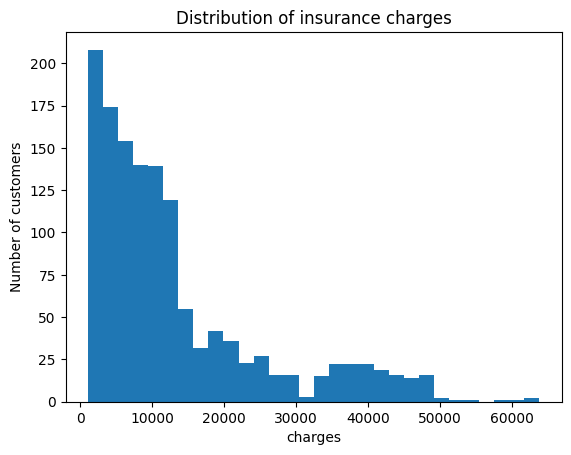

In [7]:
print(df['charges'].mean())
print(df['smoker'].value_counts())
print(df.groupby('smoker')['charges'].mean())
plt.hist(df['charges'], bins = 30 )
plt.xlabel('charges')
plt.ylabel('Number of customers')
plt.title('Distribution of insurance charges')
plt.show()

**Observation:** Most customers pay small bills, but a few pay very large ones.

smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64


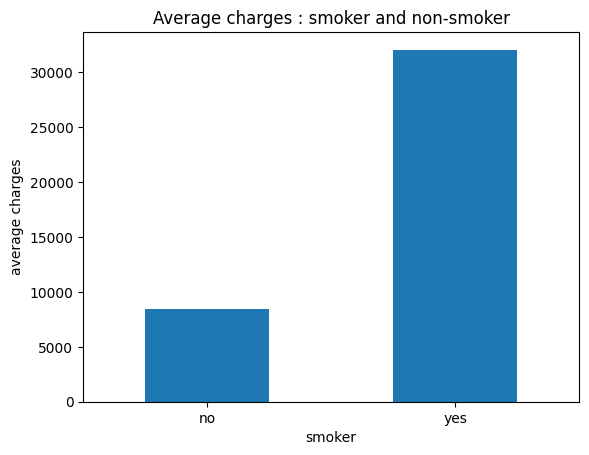

In [8]:
avg = df.groupby('smoker')['charges'].mean()
print(avg)
avg.plot(kind = 'bar')
plt.xlabel('smoker')
plt.ylabel('average charges')
plt.title('Average charges : smoker and non-smoker')
plt.xticks(rotation = 0)
plt.show()

**Observation:** Smokers pay about 3.8 times more on average than non-smokers (about $32,050 vs $8,434), so smoking looks like the biggest reason for high bills.

## Plot 3 : Charges vs Age

In [9]:
print(df['age'].corr(df['charges']))
age_charges = df.groupby('age')['charges'].mean()
print("Avgerage charges at the age of 18 : ",age_charges.loc[18])
print("Avgerage charges at the age of 64 : ",age_charges.loc[64])
increase =( 
    (age_charges.loc[64] - age_charges.loc[18]) / age_charges.loc[18]) * 100
print("Percentage increase : ",round(increase,2),"%")

0.29900819333064776
Avgerage charges at the age of 18 :  7086.217556362319
Avgerage charges at the age of 64 :  23275.530837272727
Percentage increase :  228.46 %


<function matplotlib.pyplot.show(close=None, block=None)>

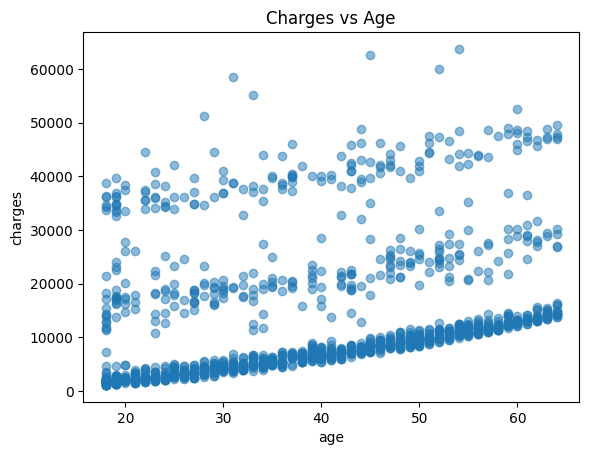

In [10]:
plt.scatter(df['age'],df['charges'], alpha=0.5)
plt.xlabel('age')
plt.ylabel('charges')
plt.title('Charges vs Age')
plt.show

**Observation :** The scatter plot shows a positive relationship between age and insurance charges increase by 228.46% from age 18 to 64, suggesting that older individuals tend to incur higher insurance costs. howeverm, age is not the only factor influencing insurance charge; Smoking status also pays a significant role

## Linear regression

In [12]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [13]:
X = df.drop('charges', axis = 1)
y = df['charges']

X = pd.get_dummies(
    X,
    columns = ['sex','smoker','region'],
    drop_first = True,
    dtype = int
)

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size = 0.2, random_state = 42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Model RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('Model R2:', r2_score(y_test, y_pred))
print(model.coef_)
print(model.intercept_)

Model RMSE: 5796.2846592762735
Model R2: 0.7835929767120723
[ 2.56975706e+02  3.37092552e+02  4.25278784e+02 -1.85916916e+01
  2.36511289e+04 -3.70677326e+02 -6.57864297e+02 -8.09799354e+02]
-11931.219050326692


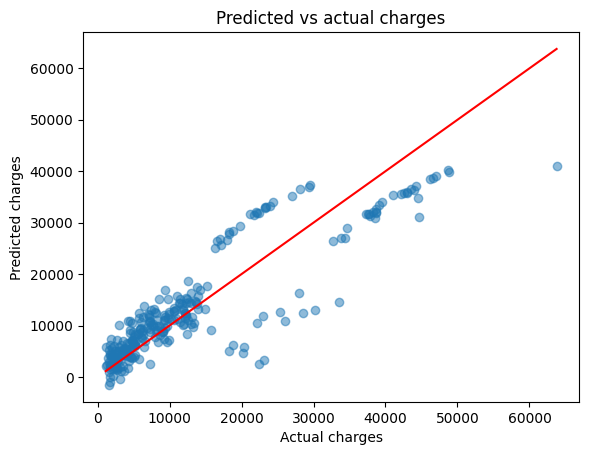

In [19]:
# 5. Predicted vs actual
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Actual charges')
plt.ylabel('Predicted charges')
plt.title('Predicted vs actual charges')
plt.show()

In [20]:
weights = pd.Series(model.coef_, index=X.columns).sort_values()
print(weights)
print('Intercept:', model.intercept_)

region_southwest     -809.799354
region_southeast     -657.864297
region_northwest     -370.677326
sex_male              -18.591692
age                   256.975706
bmi                   337.092552
children              425.278784
smoker_yes          23651.128856
dtype: float64
Intercept: -11931.219050326692


Weights (what the model learned):

Smoking is by far the biggest factor. Being a smoker adds about $23,650 to the predicted yearly bill, when age, BMI, children, sex and region are kept the same.

Age, BMI and children add smaller amounts. Each extra year of age adds about $257, each extra BMI point adds about $337, and each child adds about $425.

Sex has almost no effect (about -$19). Region has a small effect compared with the northeast: the southwest is about $810 lower, the southeast is about $658 lower, and the northwest is about $371 lower.

These weights show links in this data, not proof of cause. A straight-line model also adds each factor separately, so it cannot capture that smoking and high BMI together may cost more than the two added up.

In [30]:
def ask_and_predict():
    age = int(input('Age: '))
    bmi = float(input('BMI: '))
    children = int(input('Number of children: '))
    sex = input('Sex (male/female): ').strip().lower()
    smoker = input('Smoker (yes/no): ').strip().lower()
    region = input('Region (northeast/northwest/southeast/southwest): ').strip().lower()
    
    new_customer = pd.DataFrame([{
        'age': age,
        'bmi': bmi,
        'children': children,
        'sex_male': 1 if sex == 'male' else 0,
        'smoker_yes': 1 if smoker == 'yes' else 0,
        'region_northwest': 1 if region == 'northwest' else 0,
        'region_southeast': 1 if region == 'southeast' else 0,
        'region_southwest': 1 if region == 'southwest' else 0
    }])
    
    new_customer = new_customer[X.columns]
    prediction = model.predict(new_customer)[0]
    print(f'Predicted yearly insurance charges: ${prediction:,.2f}')

ask_and_predict()

Age:  12
BMI:  32
Number of children:  0
Sex (male/female):  male
Smoker (yes/no):  no
Region (northeast/northwest/southeast/southwest):  south


Predicted yearly insurance charges: $1,920.86
